<a href="https://colab.research.google.com/github/Murcha1990/ML_AI26/blob/main/Week3_GD_Features/GradientDescentBase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Производная, градиент и градиентный спуск

## План занятия

1. Производные: вспоминаем и проверяем себя в Python
2. Градиентный спуск в одномерном случае
3. Как шаг и начальная точка влияют на результат
4. Градиент функции нескольких переменных и градиентный спуск на плоскости
5. Векторная реализация градиентного спуска для линейной регрессии
6. Зачем масштабировать признаки
7. Градиентный спуск в sklearn

## Задание 1 (на доске)

Исследовать функцию $f(x)=x^3 - 3x^2 + 4$:
- найти локальные экстремумы и определить их тип
- найти точки перегиба

## Задание 2

Проверить себя в Python.

Для символьных вычислений в Python есть библиотека **SymPy**. Она умеет брать производные и решать уравнения «как на бумаге», поэтому ей удобно проверять ручные выкладки. В Colab SymPy уже установлена.

Важно: в машинном обучении производные обычно **не** считают символьно.
* Для простых моделей (например, линейной регрессии) градиент выписывают руками и записывают в NumPy. Так мы сделаем ниже.
* В нейросетях используют **автоматическое дифференцирование** (PyTorch, JAX, TensorFlow). Библиотека сама считает градиент по коду функции.

Поэтому SymPy нужна нам только в этом задании, а дальше будем работать с NumPy.

Подробнее про SymPy: [документация](https://docs.sympy.org/latest/tutorials/intro-tutorial/calculus.html).

In [1]:
import sympy as sp

x = sp.Symbol('x')
sp.diff(x**6)

6*x**5

Теперь вычислим производную функции из условия задания.

Для этого напишем функцию, задающую зависимость $f(x)$. Она работает и с обычными числами, и с символом SymPy.

In [2]:
def f(x):
    return x**3 - 3*x**2 + 4

In [3]:
f(0)

4

Чтобы найти нули функции, надо решить уравнение $f(x)=0$. В SymPy для этого есть функция `solve`.

In [4]:
sp.solve(f(x), x)   # f(x) = 0 относительно x

[-1, 2]

Теперь найдем производную функции $f(x)$ и затем её нули, чтобы найти экстремумы.

In [5]:
df_x = sp.diff(f(x), x)
df_x

3*x**2 - 6*x

In [6]:
sp.solve(df_x, x)

[0, 2]

In [7]:
f(0), f(2)

(4, 0)

Результат `sp.diff` — это **выражение** SymPy, а не функция Python. Поэтому `df_x(0)` вызовет ошибку `TypeError: 'Add' object is not callable`.

Подставить значение можно двумя способами:
* `.subs(x, значение)` — подстановка в выражение;
* `sp.lambdify(x, выражение)` — превращает выражение в обычную функцию Python (быструю, работает с массивами NumPy).

In [8]:
print(df_x.subs(x, 10))

df_numeric = sp.lambdify(x, df_x)
print(df_numeric(10))

240
240


Найдем нули второй производной для определения точек перегиба функции.

In [9]:
d2f_x = sp.diff(df_x, x)
d2f_x

6*x - 6

In [10]:
sp.solve(d2f_x, x)

[1]

In [11]:
f(1)

2

Знак второй производной в критических точках показывает тип экстремума: если $f''>0$ — минимум, если $f''<0$ — максимум.

In [12]:
d2f_x.subs(x, 0), d2f_x.subs(x, 2)

(-6, 6)

## Задание 3

- Нарисовать график функции $f(x)$, подписать оси
- Отметить на графике экстремумы и точку перегиба
- Напечатать под графиком при помощи *Markdown* экстремумы, точки перегиба и значения функции $f(x)$ в этих точках

In [13]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

Нарисуем график функции $f(x)$. Функция `f` написана через арифметические операции, поэтому её можно применить сразу ко всему массиву NumPy — цикл не нужен.

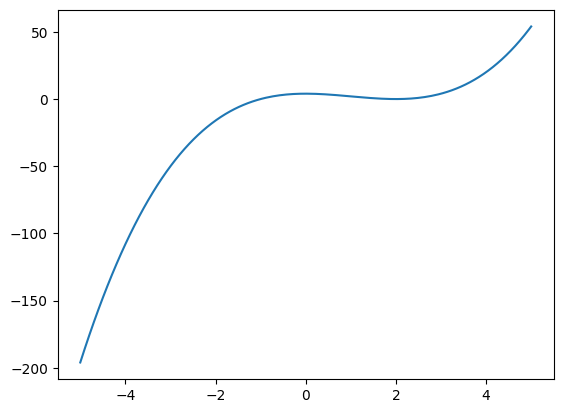

In [14]:
x_values = np.linspace(-5, 5, 200)
f_values = f(x_values)

plt.plot(x_values, f_values);

Ограничим оси, чтобы сделать картинку понятнее, добавим подписи, оси координат и отметим особые точки.

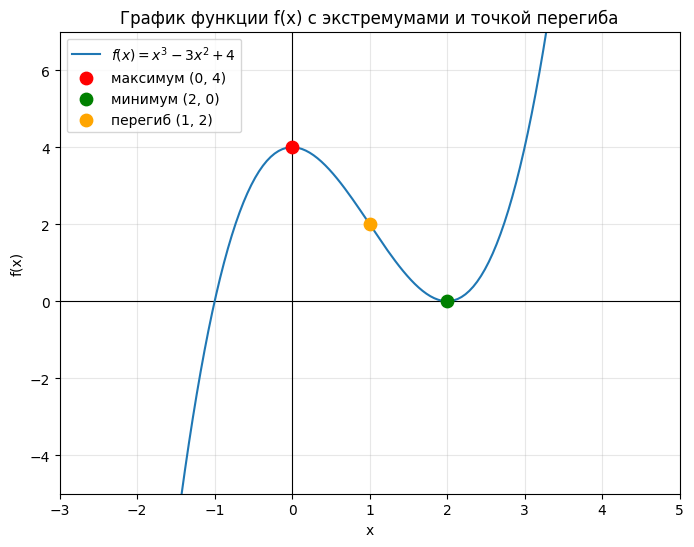

In [15]:
plt.figure(figsize=(8, 6))

plt.axvline(x=0, c='black', lw=0.8)
plt.axhline(y=0, c='black', lw=0.8)

plt.plot(x_values, f_values, label='$f(x)=x^3-3x^2+4$')

plt.scatter([0], [f(0)], c='red', s=80, zorder=3, label='максимум (0, 4)')
plt.scatter([2], [f(2)], c='green', s=80, zorder=3, label='минимум (2, 0)')
plt.scatter([1], [f(1)], c='orange', s=80, zorder=3, label='перегиб (1, 2)')

plt.xlim([-3, 5])
plt.ylim([-5, 7])

plt.title('График функции f(x) c экстремумами и точкой перегиба')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Экстремумы:
*    (0, 4) — точка локального максимума
*    (2, 0) — точка локального минимума

Точки перегиба:
*    (1, 2) — точка перегиба

Обратите внимание: глобального минимума у функции нет — при $x \to -\infty$ она уходит в $-\infty$. Это пригодится нам при обсуждении градиентного спуска.

## Градиентный спуск. Теория

Хотим найти минимум функции $f(x)$, но решать уравнение $f'(x)=0$ аналитически не хотим (или не можем).

Идея: производная показывает, в какую сторону функция растёт. Значит, чтобы функция уменьшалась, нужно сделать шаг **в противоположную сторону**:

$$x_{new} = x - \lambda\cdot f'(x)$$

* $\lambda$ — **шаг градиентного спуска** (learning rate). Он задаёт длину шага.
* Шаги повторяем, пока не сработает **критерий остановки**:
  * изменение $x$ стало маленьким: $|x_{new} - x| < \varepsilon$;
  * или закончился лимит итераций.

## Задание 4

Написать градиентный спуск в Python.

Производную мы уже нашли: $f'(x) = 3x^2 - 6x$. Запишем её обычной функцией — так работают и настоящие реализации в ML.

In [16]:
def df(x):
    return 3*x**2 - 6*x

In [17]:
def gradient_descent(df, x_start, learning_rate, epsilon=1e-6, num_iterations=1000):
    x_curr = x_start
    trace = [x_curr]

    for i in range(num_iterations):
        x_new = x_curr - learning_rate * df(x_curr)
        trace.append(x_new)

        if abs(x_new) > 1e6:  # защита от «улёта» в бесконечность
            print(f'Метод разошёлся на итерации {i + 1}')
            break

        if abs(x_new - x_curr) < epsilon:
            break

        x_curr = x_new

    return x_new, np.array(trace)

In [18]:
xmin, trace = gradient_descent(df, x_start=3, learning_rate=0.01)
print(f'Найденный минимум: x = {xmin:.4f}, итераций: {len(trace) - 1}')

Найденный минимум: x = 2.0000, итераций: 172


Напишем функцию, которая рисует траекторию спуска на графике функции. Она пригодится нам несколько раз.

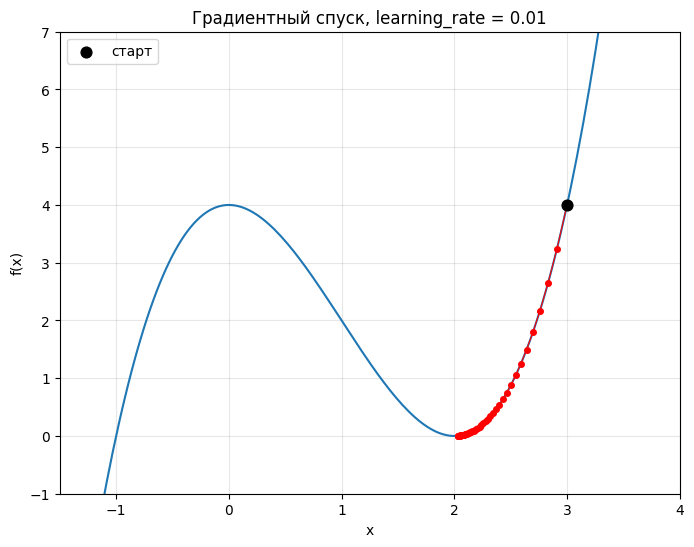

In [19]:
def plot_trace(trace, title='', ax=None, max_points=50):
    if ax is None:
        ax = plt.gca()
    x_values = np.linspace(-1.5, 4, 200)
    ax.plot(x_values, f(x_values))

    trace = trace[:max_points]
    ax.plot(trace, f(trace), 'o-', c='red', ms=4, lw=0.8)
    ax.scatter(trace[0], f(trace[0]), c='black', s=60, zorder=3, label='старт')

    ax.set_xlim([-1.5, 4])
    ax.set_ylim([-1, 7])
    ax.set_xlabel('x')
    ax.set_ylabel('f(x)')
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)

plt.figure(figsize=(8, 6))
plot_trace(trace, 'Градиентный спуск, learning_rate = 0.01')
plt.show()

## Задание 5. Влияние шага

Запустите градиентный спуск из точки $x_0 = 3$ с разными шагами: 0.01, 0.1, 0.3, 0.4. Что происходит?

Метод разошёлся на итерации 6


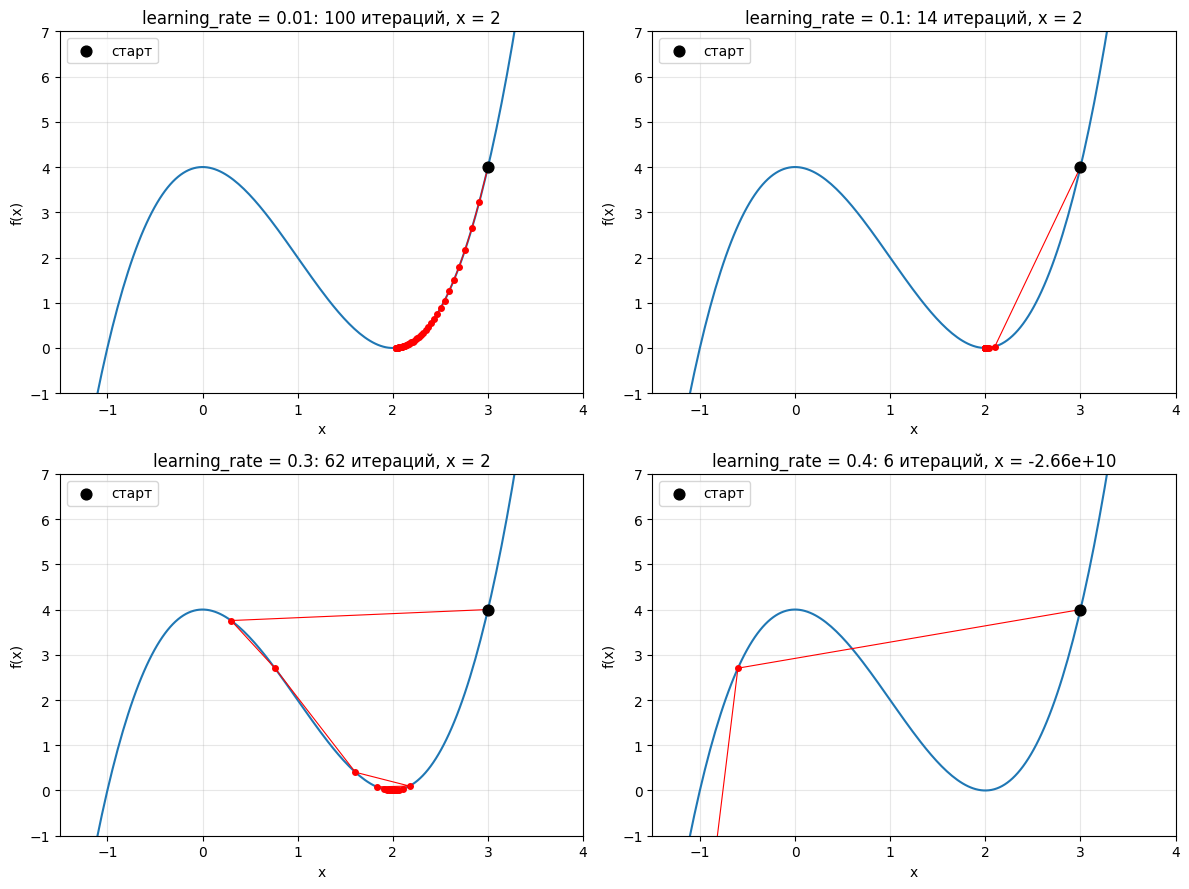

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, lr in zip(axes.ravel(), [0.01, 0.1, 0.3, 0.4]):
    xmin, trace = gradient_descent(df, x_start=3, learning_rate=lr, num_iterations=100)
    plot_trace(trace, f'learning_rate = {lr}: {len(trace) - 1} итераций, x = {xmin:.3g}', ax=ax)

plt.tight_layout()
plt.show()

Выводы:
* **маленький шаг** — сходимся, но медленно;
* **подходящий шаг** — быстро сходимся;
* **большой шаг** — точка «прыгает» вокруг минимума (осцилляции);
* **слишком большой шаг** — метод перепрыгивает минимум (здесь даже через максимум попадает на левую ветку) и расходится.

Подбор шага — одна из главных практических проблем градиентного спуска. В продвинутой части мы увидим, как максимальный безопасный шаг связан с кривизной функции.

## Задание 6. Влияние начальной точки

Запустите градиентный спуск с шагом 0.1 из точек $x_0 = 3$, $x_0 = 0.5$, $x_0 = 0$ и $x_0 = -0.5$. Объясните результат.

Метод разошёлся на итерации 8


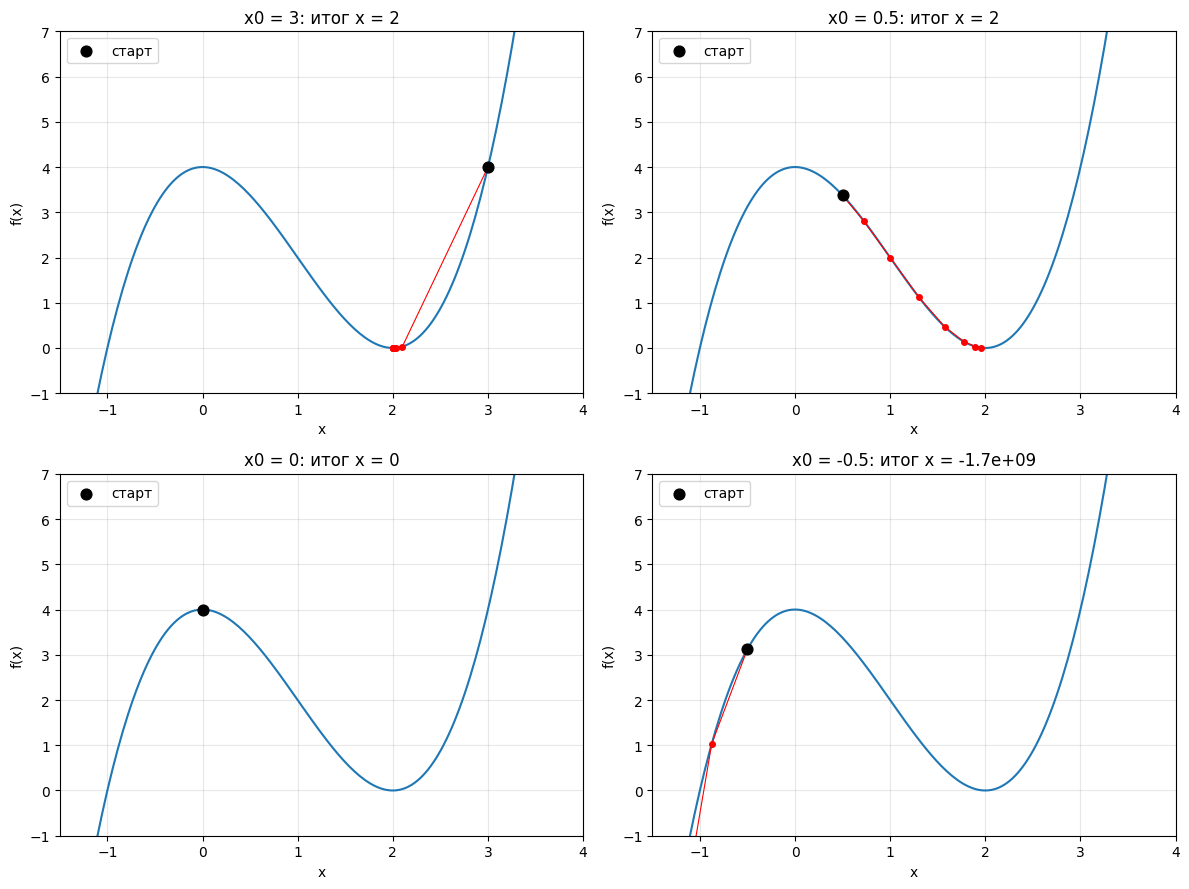

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, x0 in zip(axes.ravel(), [3, 0.5, 0, -0.5]):
    xmin, trace = gradient_descent(df, x_start=x0, learning_rate=0.1, num_iterations=100)
    plot_trace(trace, f'x0 = {x0}: итог x = {xmin:.3g}', ax=ax, max_points=8)

plt.tight_layout()
plt.show()

Выводы:
* градиентный спуск находит **локальный** минимум — тот, в «яму» которого мы попали;
* из точки $x_0 = 0$ метод не сдвинется: там $f'(0)=0$, хотя это **максимум**. Градиентный спуск останавливается в любой точке, где производная равна нулю;
* из точки $x_0 = -0.5$ метод уходит влево и расходится: минимума слева нет, функция убывает до $-\infty$.

## Градиент функции нескольких переменных

В машинном обучении функция потерь зависит не от одного числа, а от вектора весов $w = (w_1, \dots, w_d)$.

**Градиент** — это вектор из частных производных:

$$\nabla f(w) = \left(\frac{\partial f}{\partial w_1}, \dots, \frac{\partial f}{\partial w_d}\right)$$

Градиент указывает направление **наискорейшего роста** функции. Поэтому формула градиентного спуска выглядит так же, как в одномерном случае:

$$w_{new} = w - \lambda \nabla f(w)$$

Пример: $f(w_1, w_2) = w_1^2 + 5w_2^2$. Тогда $\nabla f(w) = (2w_1,\ 10w_2)$.

In [22]:
def f2(w):
    return w[0]**2 + 5 * w[1]**2

def grad_f2(w):
    return np.array([2 * w[0], 10 * w[1]])

def gradient_descent_2d(grad, w_start, learning_rate, num_iterations=50):
    w = np.array(w_start, dtype=float)
    trace = [w.copy()]
    for i in range(num_iterations):
        w = w - learning_rate * grad(w)
        trace.append(w.copy())
    return w, np.array(trace)

Нарисуем **линии уровня** функции (линии, на которых значение функции одинаковое) и траекторию спуска для двух шагов.

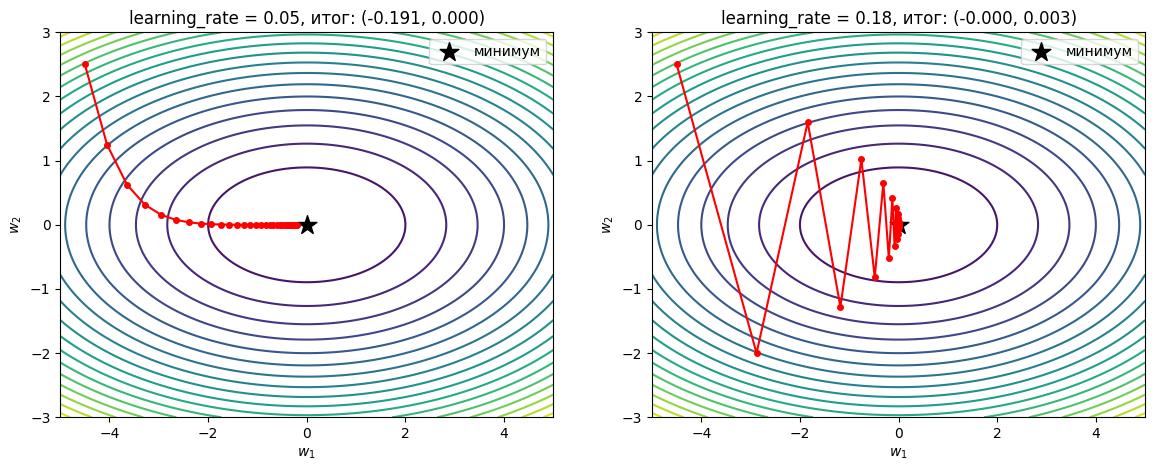

In [23]:
w1, w2 = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-3, 3, 200))
Z = w1**2 + 5 * w2**2

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, lr in zip(axes, [0.05, 0.18]):
    w_final, trace = gradient_descent_2d(grad_f2, [-4.5, 2.5], learning_rate=lr, num_iterations=30)
    ax.contour(w1, w2, Z, levels=20, cmap='viridis')
    ax.plot(trace[:, 0], trace[:, 1], 'o-', c='red', ms=4)
    ax.scatter(0, 0, marker='*', s=200, c='black', label='минимум')
    ax.set_title(f'learning_rate = {lr}, итог: ({w_final[0]:.3f}, {w_final[1]:.3f})')
    ax.set_xlabel('$w_1$')
    ax.set_ylabel('$w_2$')
    ax.legend()

plt.show()

* Градиент перпендикулярен линиям уровня, поэтому шаги идут «поперёк» эллипсов.
* Функция растягивается по осям по-разному: по $w_2$ она в 5 раз «круче». При большом шаге метод начинает метаться (зигзаг) по крутому направлению и медленно двигается по пологому.

Эта проблема часто возникает в линейной регрессии, когда признаки имеют разный масштаб. К ней мы вернёмся ниже.

# Градиентный спуск для линейной регрессии

Сгенерируем выборку для задачи регрессии и визуализируем данные. Истинная зависимость: $y = 2x + 3 + \text{шум}$.

(100, 1) (100,)


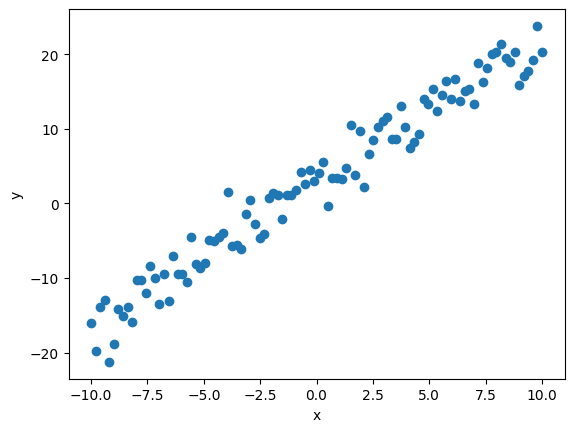

In [24]:
rng = np.random.default_rng(42)

X = np.linspace(-10, 10, 100).reshape(-1, 1)   # матрица объект-признак размера (100, 1)
y = 2 * X.ravel() + 3 + rng.normal(0, 3, size=len(X))

print(X.shape, y.shape)

plt.scatter(X, y)
plt.xlabel('x')
plt.ylabel('y');

Функция потерь — среднеквадратичная ошибка:

$$Q(w) = MSE = \frac{1}{m}\|Xw - y\|^2_2$$

* $X$ — матрица объект-признак, $m$ — число объектов, $w$ — вектор весов;
* $Xw$ — вектор предсказаний модели;
* $y$ — вектор правильных ответов.

Квадратичная ошибка — это квадрат нормы разности вектора предсказаний и вектора правильных ответов. Норму вектора посчитаем функцией `np.linalg.norm`.

In [25]:
def compute_cost(X, y, w):
    m = len(y)
    return (1. / m) * np.linalg.norm(X @ w - y) ** 2

Градиент MSE по весам:

$$\nabla_w Q(w) = \frac{2}{m}X^T(Xw - y)$$

Шаг градиентного спуска:

$$w_{new} = w_{prev} - \lambda \nabla_w Q(w_{prev})$$

Реализуем метод:

* первым шагом добавим к матрице $X$ столбец из единиц — это константный признак, равный 1 на всех объектах. Он нужен, чтобы записать предсказание линейной регрессии в виде скалярного произведения:
$a(x)=w_0+w_1x_1+\dots+w_dx_d=w_0\cdot 1+w_1x_1+\dots+w_dx_d=\langle w,x \rangle$.
В Python скалярное произведение записывается так: `w @ x`;
* затем инициализируем случайным образом вектор весов `w`;
* в массив `cost_track` будем записывать ошибку на каждой итерации;
* наконец, в цикле по числу итераций будем обновлять веса по формуле градиентного спуска.

Обратите внимание: в коде нет цикла по объектам и признакам — все вычисления записаны через матрицы. Такая **векторная** реализация в NumPy в десятки и сотни раз быстрее циклов на Python.

In [26]:
def add_ones(X):
    return np.hstack((np.ones((X.shape[0], 1)), X))


def gradient_descent_lr(X, y, learning_rate, iterations, seed=0):
    X = add_ones(X)
    w = np.random.default_rng(seed).random(X.shape[1])

    m = X.shape[0]
    cost_track = np.zeros(iterations)

    for i in range(iterations):
        gradient = 2. / m * X.T @ (X @ w - y)
        w = w - learning_rate * gradient
        cost_track[i] = compute_cost(X, y, w)

    return cost_track, w


def predict(X, w):
    return add_ones(X) @ w

Применим градиентный спуск.

Веса (w0, w1): [2.84910041 1.93707074]


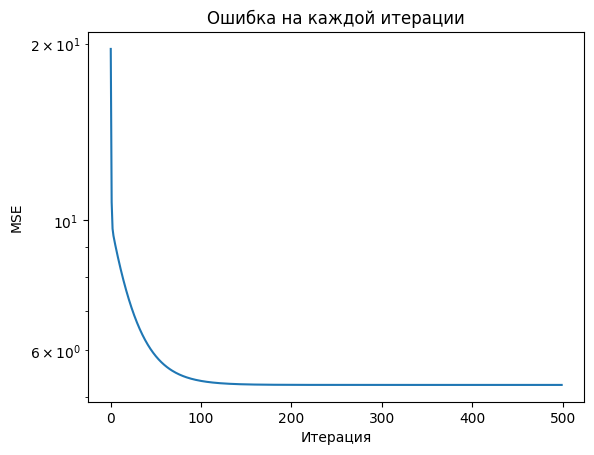

In [27]:
track, weights = gradient_descent_lr(X, y, learning_rate=0.01, iterations=500)
print('Веса (w0, w1):', weights)

plt.plot(track)
plt.yscale('log')
plt.xlabel('Итерация')
plt.ylabel('MSE')
plt.title('Ошибка на каждой итерации');

Сравним с аналитическим решением из sklearn. Веса должны почти совпасть.

In [28]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression().fit(X, y)
print('sklearn:  w0 =', lr_model.intercept_, ' w1 =', lr_model.coef_[0])
print('наш GD:   w0 =', weights[0], ' w1 =', weights[1])

sklearn:  w0 = 2.8491911655484263  w1 = 1.9370707449444138
наш GD:   w0 = 2.849100411079174  w1 = 1.9370707449444136


Добавим к графику полученную регрессионную прямую.

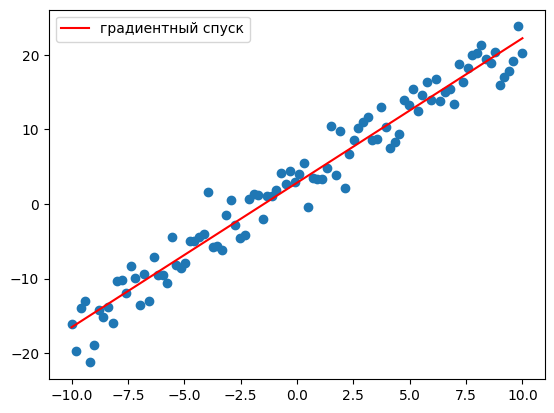

In [29]:
pred = predict(X, weights)

plt.scatter(X, y)
plt.plot(X, pred, '-', c='r', label='градиентный спуск')
plt.legend();

**Вопрос:** запустите спуск на 10, 50 и 500 итераций и посмотрите на веса. Заметили, что $w_1$ находится почти сразу, а свободный член $w_0$ сходится заметно медленнее? Причина та же, что и в примере с эллипсами: признак $x$ меняется от −10 до 10, а константный признак всегда равен 1. Масштабы разные — сходимость по разным весам разная.

In [30]:
for iterations in [10, 50, 500]:
    _, w = gradient_descent_lr(X, y, learning_rate=0.01, iterations=iterations)
    print(f'{iterations:>3} итераций: w0 = {w[0]:.3f}, w1 = {w[1]:.3f}')

 10 итераций: w0 = 1.042, w1 = 1.937
 50 итераций: w0 = 2.044, w1 = 1.937
500 итераций: w0 = 2.849, w1 = 1.937


## Задание 7. Масштабирование признаков

Возьмём данные с двумя признаками разного масштаба: площадь квартиры (30–150 м²) и число комнат (1–5). Сравним градиентный спуск на исходных и на стандартизованных признаках.

In [31]:
rng = np.random.default_rng(0)
m = 500
area = rng.uniform(30, 150, m)
rooms = rng.integers(1, 6, m)
price = 0.1 * area + 0.5 * rooms + 1 + rng.normal(0, 0.5, m)   # цена в млн рублей

X_flat = np.column_stack([area, rooms])
print('Средние признаков:', X_flat.mean(axis=0))
print('Стандартные отклонения:', X_flat.std(axis=0))

Средние признаков: [93.69119706  3.048     ]
Стандартные отклонения: [34.58341394  1.3991769 ]


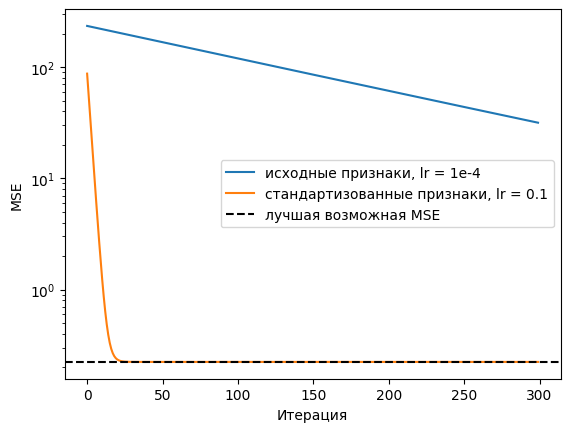

In [32]:
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X_flat)

# на исходных данных приходится брать очень маленький шаг, иначе метод расходится
track_raw, _ = gradient_descent_lr(X_flat, price, learning_rate=1e-4, iterations=300)
track_scaled, _ = gradient_descent_lr(X_scaled, price, learning_rate=0.1, iterations=300)

best = LinearRegression().fit(X_flat, price)
best_mse = np.mean((best.predict(X_flat) - price) ** 2)

plt.plot(track_raw, label='исходные признаки, lr = 1e-4')
plt.plot(track_scaled, label='стандартизованные признаки, lr = 0.1')
plt.axhline(best_mse, c='black', ls='--', label='лучшая возможная MSE')
plt.yscale('log')
plt.xlabel('Итерация')
plt.ylabel('MSE')
plt.legend();

Попробуйте увеличить шаг для исходных признаков, например до `1e-3`. Что произойдёт?

In [33]:
track_raw_big, _ = gradient_descent_lr(X_flat, price, learning_rate=1e-3, iterations=20)
print(track_raw_big[:10])

[8.47255865e+04 3.04768084e+07 1.09630065e+10 3.94357291e+12
 1.41856773e+15 5.10282034e+17 1.83556801e+20 6.60283860e+22
 2.37514913e+25 8.54380023e+27]


Вывод: **перед градиентным спуском признаки нужно масштабировать** (например, `StandardScaler`). Иначе безопасный шаг определяется признаком с самым большим масштабом, и по остальным весам метод движется очень медленно.

# Градиентный спуск в sklearn

Сгенерируем выборку для задачи регрессии: 10000 объектов, 100 признаков и немного шума.

In [34]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

X, y = make_regression(n_samples=10000, n_features=100, noise=10, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(8000, 100) (2000, 100)


Сначала решим задачу аналитически «из коробки».

In [35]:
lr = LinearRegression()
lr.fit(X_train, y_train)

print('MSE на тесте:', mean_squared_error(y_test, lr.predict(X_test)))

MSE на тесте: 103.19177035099158


Теперь обучим линейную регрессию градиентным спуском «из коробки» — классом `SGDRegressor`.

Это **стохастический** градиентный спуск: на каждом шаге градиент считается не по всей выборке, а по одному объекту. Шаги получаются дешёвыми, поэтому метод подходит для больших данных.

Основные параметры:
* `eta0` — начальный шаг градиентного спуска;
* `learning_rate` — как меняется шаг со временем (`'invscaling'` — по умолчанию, шаг постепенно уменьшается; `'constant'` — шаг постоянный);
* `max_iter` — максимальное число эпох (проходов по выборке);
* `alpha` — коэффициент **регуляризации** (это **не** шаг!);
* `penalty` — тип регуляризации (`'l2'` по умолчанию, можно `None`).

Признаки в `make_regression` уже имеют одинаковый масштаб. На реальных данных перед `SGDRegressor` их нужно стандартизовать.

In [36]:
from sklearn.linear_model import SGDRegressor

sgd = SGDRegressor(random_state=42)
sgd.fit(X_train, y_train)

print('MSE на тесте:', mean_squared_error(y_test, sgd.predict(X_test)))
print('Число эпох:', sgd.n_iter_)

MSE на тесте: 103.93563645697839
Число эпох: 38


Сравним веса двух моделей. В `make_regression` по умолчанию только 10 признаков из 100 действительно влияют на ответ, поэтому посмотрим на 5 самых больших весов.

In [37]:
top = np.argsort(-np.abs(lr.coef_))[:5]
print('Номера признаков:', top)
print('LinearRegression:', lr.coef_[top].round(2))
print('SGDRegressor:    ', sgd.coef_[top].round(2))

Номера признаков: [49 52 86 48 47]
LinearRegression: [90.2  84.95 82.63 71.61 63.3 ]
SGDRegressor:     [90.   84.97 82.77 71.74 63.3 ]


Попробуйте разные значения шага `eta0` (например, 0.0001, 0.001, 0.01, 0.1). Как меняются ошибка и число эпох?

In [38]:
for eta0 in [0.0001, 0.001, 0.01, 0.1]:
    sgd = SGDRegressor(eta0=eta0, random_state=42).fit(X_train, y_train)
    print(f'eta0 = {eta0:<7} MSE = {mean_squared_error(y_test, sgd.predict(X_test)):10.2f}   эпох: {sgd.n_iter_}')

eta0 = 0.0001  MSE =     103.06   эпох: 263
eta0 = 0.001   MSE =     103.19   эпох: 67
eta0 = 0.01    MSE =     103.94   эпох: 38
eta0 = 0.1     MSE =     122.66   эпох: 63


## Итоги

* Градиентный спуск делает шаги против градиента и находит **локальный** минимум.
* Результат зависит от шага и начальной точки. Слишком большой шаг приводит к расходимости, слишком маленький — к медленной сходимости.
* Для линейной регрессии градиент MSE записывается в векторном виде: $\frac{2}{m}X^T(Xw - y)$.
* Перед градиентным спуском признаки нужно масштабировать.
* В sklearn градиентный спуск для линейных моделей реализован в `SGDRegressor` и `SGDClassifier`.